In [5]:
import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np



# Task 1

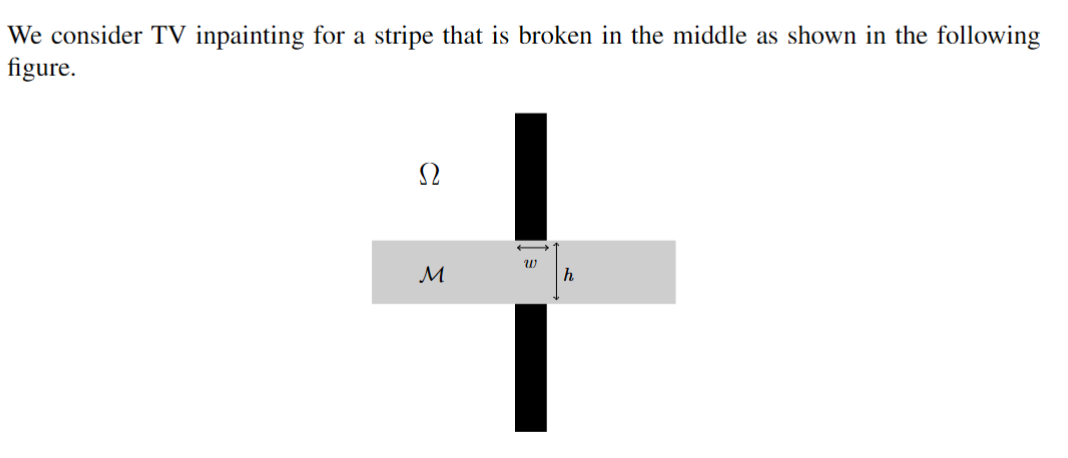
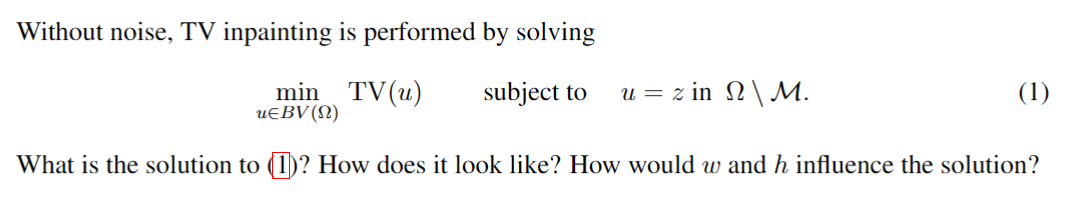
See physical notebook

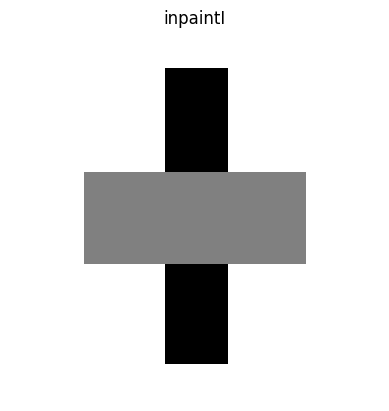

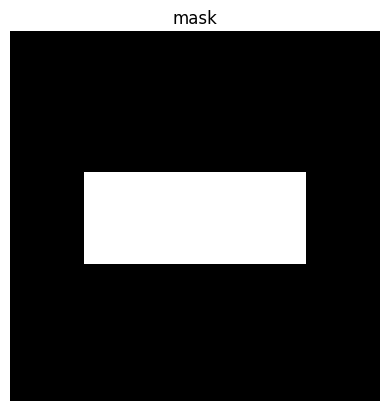

In [ ]:
### Stripe.py from Learn
# parameters
w = 17
halfw = w // 2           # floor(w/2)
h = 25
halfh = h // 2           # floor(h/2)

# generate the test image
inpaintI = np.ones((100, 100), dtype=float)

cols_start_mat = 50 - halfw + 1
cols_end_mat   = 50 - halfw + w
rows_slice1 = slice(11 - 1, 90)
cols_slice1 = slice(cols_start_mat - 1, cols_end_mat)

inpaintI[rows_slice1, cols_slice1] = 0.0

# generate mask
mask = np.zeros((100, 100), dtype=bool)

rows_start_mat = 50 - halfh + 1
rows_end_mat   = 50 - halfh + h
rows_slice2 = slice(rows_start_mat - 1, rows_end_mat)
cols_slice2 = slice(21 - 1, 80)

mask[rows_slice2, cols_slice2] = True

# Apply mask
inpaintI[mask] = 0.5

# Display
plt.figure()
plt.imshow(inpaintI, cmap='gray', vmin=0, vmax=1)
plt.axis('off')
plt.title('inpaintI')

plt.figure()
plt.imshow(mask, cmap='gray')
plt.axis('off')
plt.title('mask')

plt.show()


# Task 2
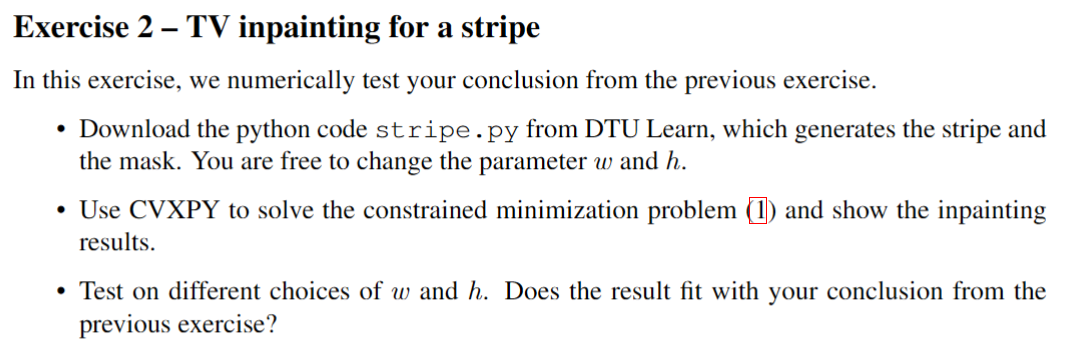

Text(0.5, 1.0, 'solution')

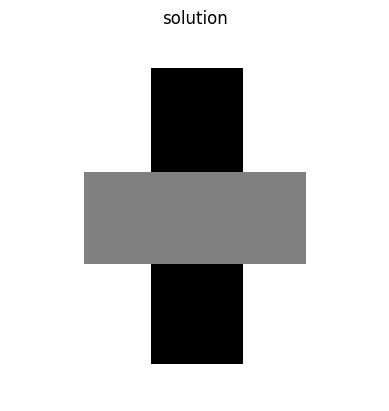

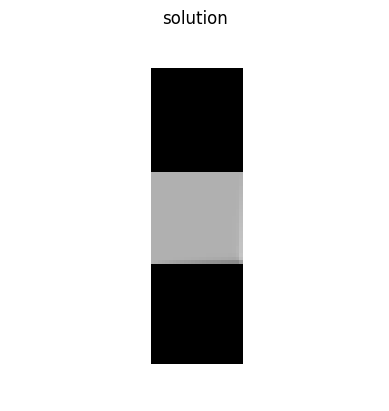

In [ ]:

# Problem data.
w = 25
halfw = w // 2           # floor(w/2)
h = 25
halfh = h // 2           # floor(h/2)

# generate the test image
inpaintI = np.ones((100, 100), dtype=float)

cols_start_mat = 50 - halfw + 1
cols_end_mat   = 50 - halfw + w
rows_slice1 = slice(11 - 1, 90)
cols_slice1 = slice(cols_start_mat - 1, cols_end_mat)

inpaintI[rows_slice1, cols_slice1] = 0.0

# generate mask
mask = np.zeros((100, 100), dtype=bool)

rows_start_mat = 50 - halfh + 1
rows_end_mat   = 50 - halfh + h
rows_slice2 = slice(rows_start_mat - 1, rows_end_mat)
cols_slice2 = slice(21 - 1, 80)

mask[rows_slice2, cols_slice2] = True

inpaintI[mask] = 0.5

N = mask.shape[0]
assert N == mask.shape[1], "Image must be square"
u = cp.Variable((N, N))
objective = cp.Minimize(cp.tv(u))
constraint = [u[~mask] == inpaintI[~mask]]
problem = cp.Problem(objective, constraint)
result = problem.solve()

plt.figure()
plt.imshow(inpaintI, cmap='gray', vmin=0, vmax=1)
plt.axis('off')
plt.title('solution')
plt.figure()
plt.imshow(u.value, cmap='gray', vmin=0, vmax=1)
plt.axis('off')
plt.title('solution')

# Changing w/h changes as expected and explained in task 1.


# Task 3

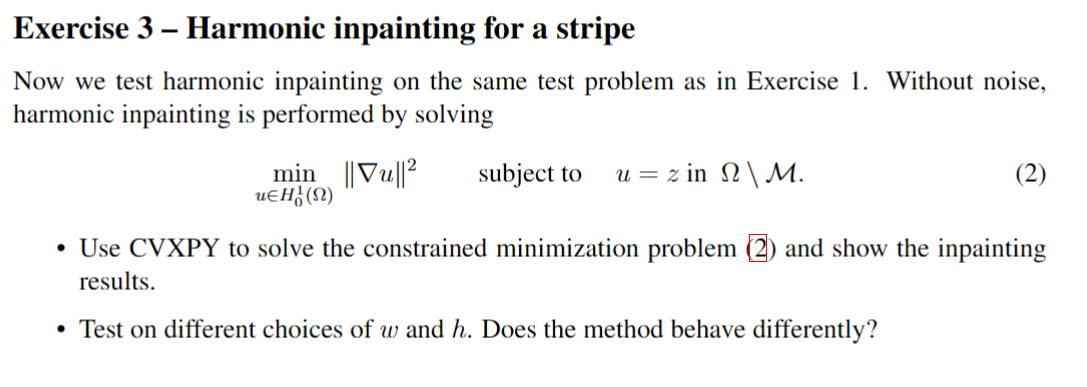

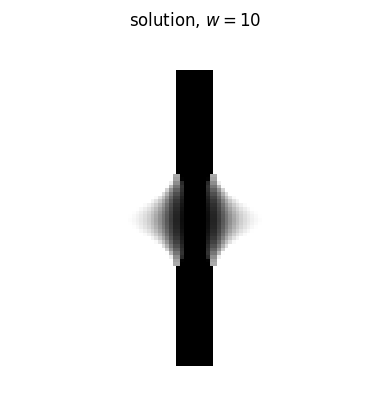

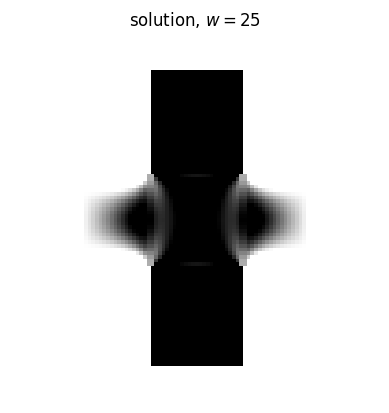

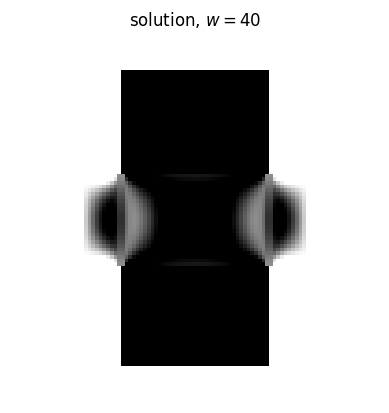

In [30]:
for w in [10, 25, 40]:
    # Problem data.
    halfw = w // 2           # floor(w/2)
    h = 25
    halfh = h // 2           # floor(h/2)

    # generate the test image
    inpaintI = np.ones((100, 100), dtype=float)

    cols_start_mat = 50 - halfw + 1
    cols_end_mat   = 50 - halfw + w
    rows_slice1 = slice(11 - 1, 90)
    cols_slice1 = slice(cols_start_mat - 1, cols_end_mat)

    inpaintI[rows_slice1, cols_slice1] = 0.0

    # generate mask
    mask = np.zeros((100, 100), dtype=bool)

    rows_start_mat = 50 - halfh + 1
    rows_end_mat   = 50 - halfh + h
    rows_slice2 = slice(rows_start_mat - 1, rows_end_mat)
    cols_slice2 = slice(21 - 1, 80)

    mask[rows_slice2, cols_slice2] = True

    inpaintI[mask] = 0.5

    N = mask.shape[0]
    assert N == mask.shape[1], "Image must be square"
    u = cp.Variable((N, N))
    grad_u_x = cp.diff(u, axis=0)
    grad_u_y = cp.diff(u, axis=1)
    objective = cp.Minimize(cp.square(cp.norm(grad_u_x, 2)) + cp.square(cp.norm(grad_u_y, 2)))
    constraint = [u[~mask] == inpaintI[~mask]]
    problem = cp.Problem(objective, constraint)
    result = problem.solve()

    plt.figure()
    plt.imshow(u.value, cmap='gray', vmin=0, vmax=1)
    plt.axis('off')
    plt.title(f'solution, $w={w}$')

    # Changing w/h changes as expected and explained in task 1.


Method clearly behaves very differently, in part because $u(x, y)$ is now a differentiable function.